# **CIFAR10 Image Classification**

This notebook explores the CIFAR10 dataset, analyzes its structure and statistical properties, defines an appropriate preprocessing pipeline, and prepares the data for model training.

##**Import necessary libraries**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader
from torch.utils.data import random_split
from torch import argmax
import copy

import sklearn.metrics as metrics
import seaborn as sns

import time
import os
import random

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# Initialize with a fixed seed
set_seed(42)

## **Part I. Exploratory Data Analysis**

The objective of this section is to understand the dataset before applying preprocessing or training a machine learning model.

## **Load train dataset for EDA**

In [ ]:
full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    download=True,
    train=True
)

100%|██████████| 170M/170M [31:42<00:00, 89.6kB/s]


##**Dataset Size**

In [ ]:
print("Train:", len(full_train_dataset))

Train: 50000


##**List all classes**

In [ ]:
print("Number of classes:", len(full_train_dataset.classes))

for idx, class_name in enumerate(full_train_dataset.classes):
    print(f"{idx}: {class_name}")

Number of classes: 10
0: airplane
1: automobile
2: bird
3: cat
4: deer
5: dog
6: frog
7: horse
8: ship
9: truck


##**Data Structure**
*The dataset structure is examined to determine the input dimensions, image representation, and whether spatial resizing or channel conversion is required.*

###**Single Sample**

IMAGE
Image type: <class 'PIL.Image.Image'>
Image size: (32, 32)
Image mode: RGB
uint8
Min: 0
Max: 255

LABEL
Label index: 6
Label name: frog

A SAMPLE


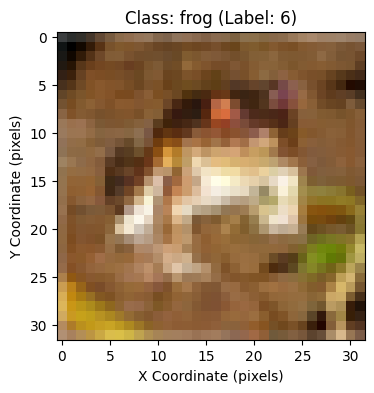

In [ ]:
image, label = full_train_dataset[0]

print("IMAGE")
print("Image type:", type(image))
print("Image size:", image.size)
print("Image mode:", image.mode)
print(full_train_dataset.data.dtype)
print("Min:", full_train_dataset.data.min().item())
print("Max:", full_train_dataset.data.max().item())

print("\nLABEL")
print("Label index:", label)
print("Label name:", full_train_dataset.classes[label])

print("\nA SAMPLE")
plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(f"Class: {full_train_dataset.classes[label]} (Label: {label})")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.grid(False)
plt.show()


###**Inspect Raw Image and Label Tensors**

In [ ]:
print("Training image tensor shape:", full_train_dataset.data.shape)
print("Training label tensor shape:", len(full_train_dataset.targets))

print("Image data type:", full_train_dataset.data.dtype)
print("Label data type:", type(full_train_dataset.targets[0]))

Training image tensor shape: (50000, 32, 32, 3)
Training label tensor shape: 50000
Image data type: uint8
Label data type: <class 'int'>


###**Data Visualization**

####**Class Distribution**
*Class distribution analysis determines whether the dataset is balanced or whether class imbalance needs to be addressed.*

In [ ]:
def plot_class_distribution(dataset, title="Training Set Class Distribution"):

    # Count the number of samples in each class
    class_counts = torch.bincount(dataset.targets)

    # Print class frequencies
    for class_idx, count in enumerate(class_counts):
        print(
            f"{dataset.classes[class_idx]:15s}: "
            f"{count.item()} samples"
        )

    # Plot class distribution
    plt.figure(figsize=(10, 5))

    # Generate colors using the 'rocket' colormap
    colors = sns.color_palette("rocket", n_colors=len(dataset.classes))

    plt.bar(
        dataset.classes,
        class_counts.numpy(),
        color=colors
    )

    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Number of Samples")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

airplane       : 5000 samples
automobile     : 5000 samples
bird           : 5000 samples
cat            : 5000 samples
deer           : 5000 samples
dog            : 5000 samples
frog           : 5000 samples
horse          : 5000 samples
ship           : 5000 samples
truck          : 5000 samples


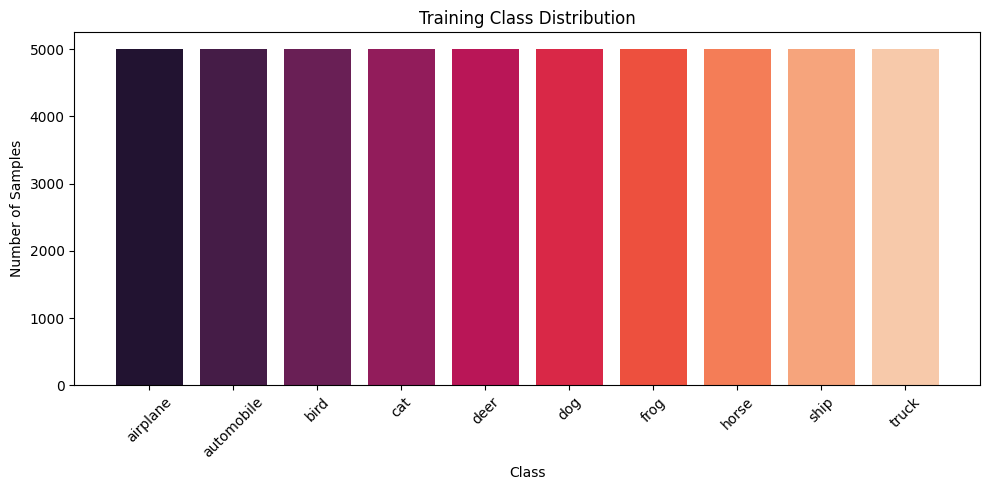

In [ ]:
if isinstance(full_train_dataset.targets, list):
    full_train_dataset.targets = torch.tensor(full_train_dataset.targets)

plot_class_distribution(full_train_dataset, title="Training Class Distribution")

#### **Some samples from Each Class**

*Multiple samples from each class are examined to assess visual similarity between different categories.*

In [ ]:
def plot_samples_per_class(dataset, samples_per_class=5):

    num_classes = len(dataset.classes)

    fig, axes = plt.subplots(
        num_classes,
        samples_per_class,
        figsize=(2 * samples_per_class, 2.8 * num_classes)
    )

    for class_idx in range(num_classes):

        # Find all samples belonging to the current class
        class_indices = torch.where(
            dataset.targets == class_idx
        )[0]

        # Randomly select samples from the current class
        selected_indices = class_indices[
            torch.randperm(len(class_indices))[:samples_per_class]
        ]

        for j, idx in enumerate(selected_indices):
            image = dataset.data[idx]

            axes[class_idx, j].imshow(
                image,
                cmap="gray"
            )

            axes[class_idx, j].axis("off")

            # Add class name below each image
            axes[class_idx, j].set_title(
                dataset.classes[class_idx],
                fontsize=12,
                y=-0.35
            )

            if j == 0:
                axes[class_idx, j].set_ylabel(
                    dataset.classes[class_idx],
                    rotation=0,
                    labelpad=50,
                    va="center"
                )

    plt.tight_layout()
    plt.show()

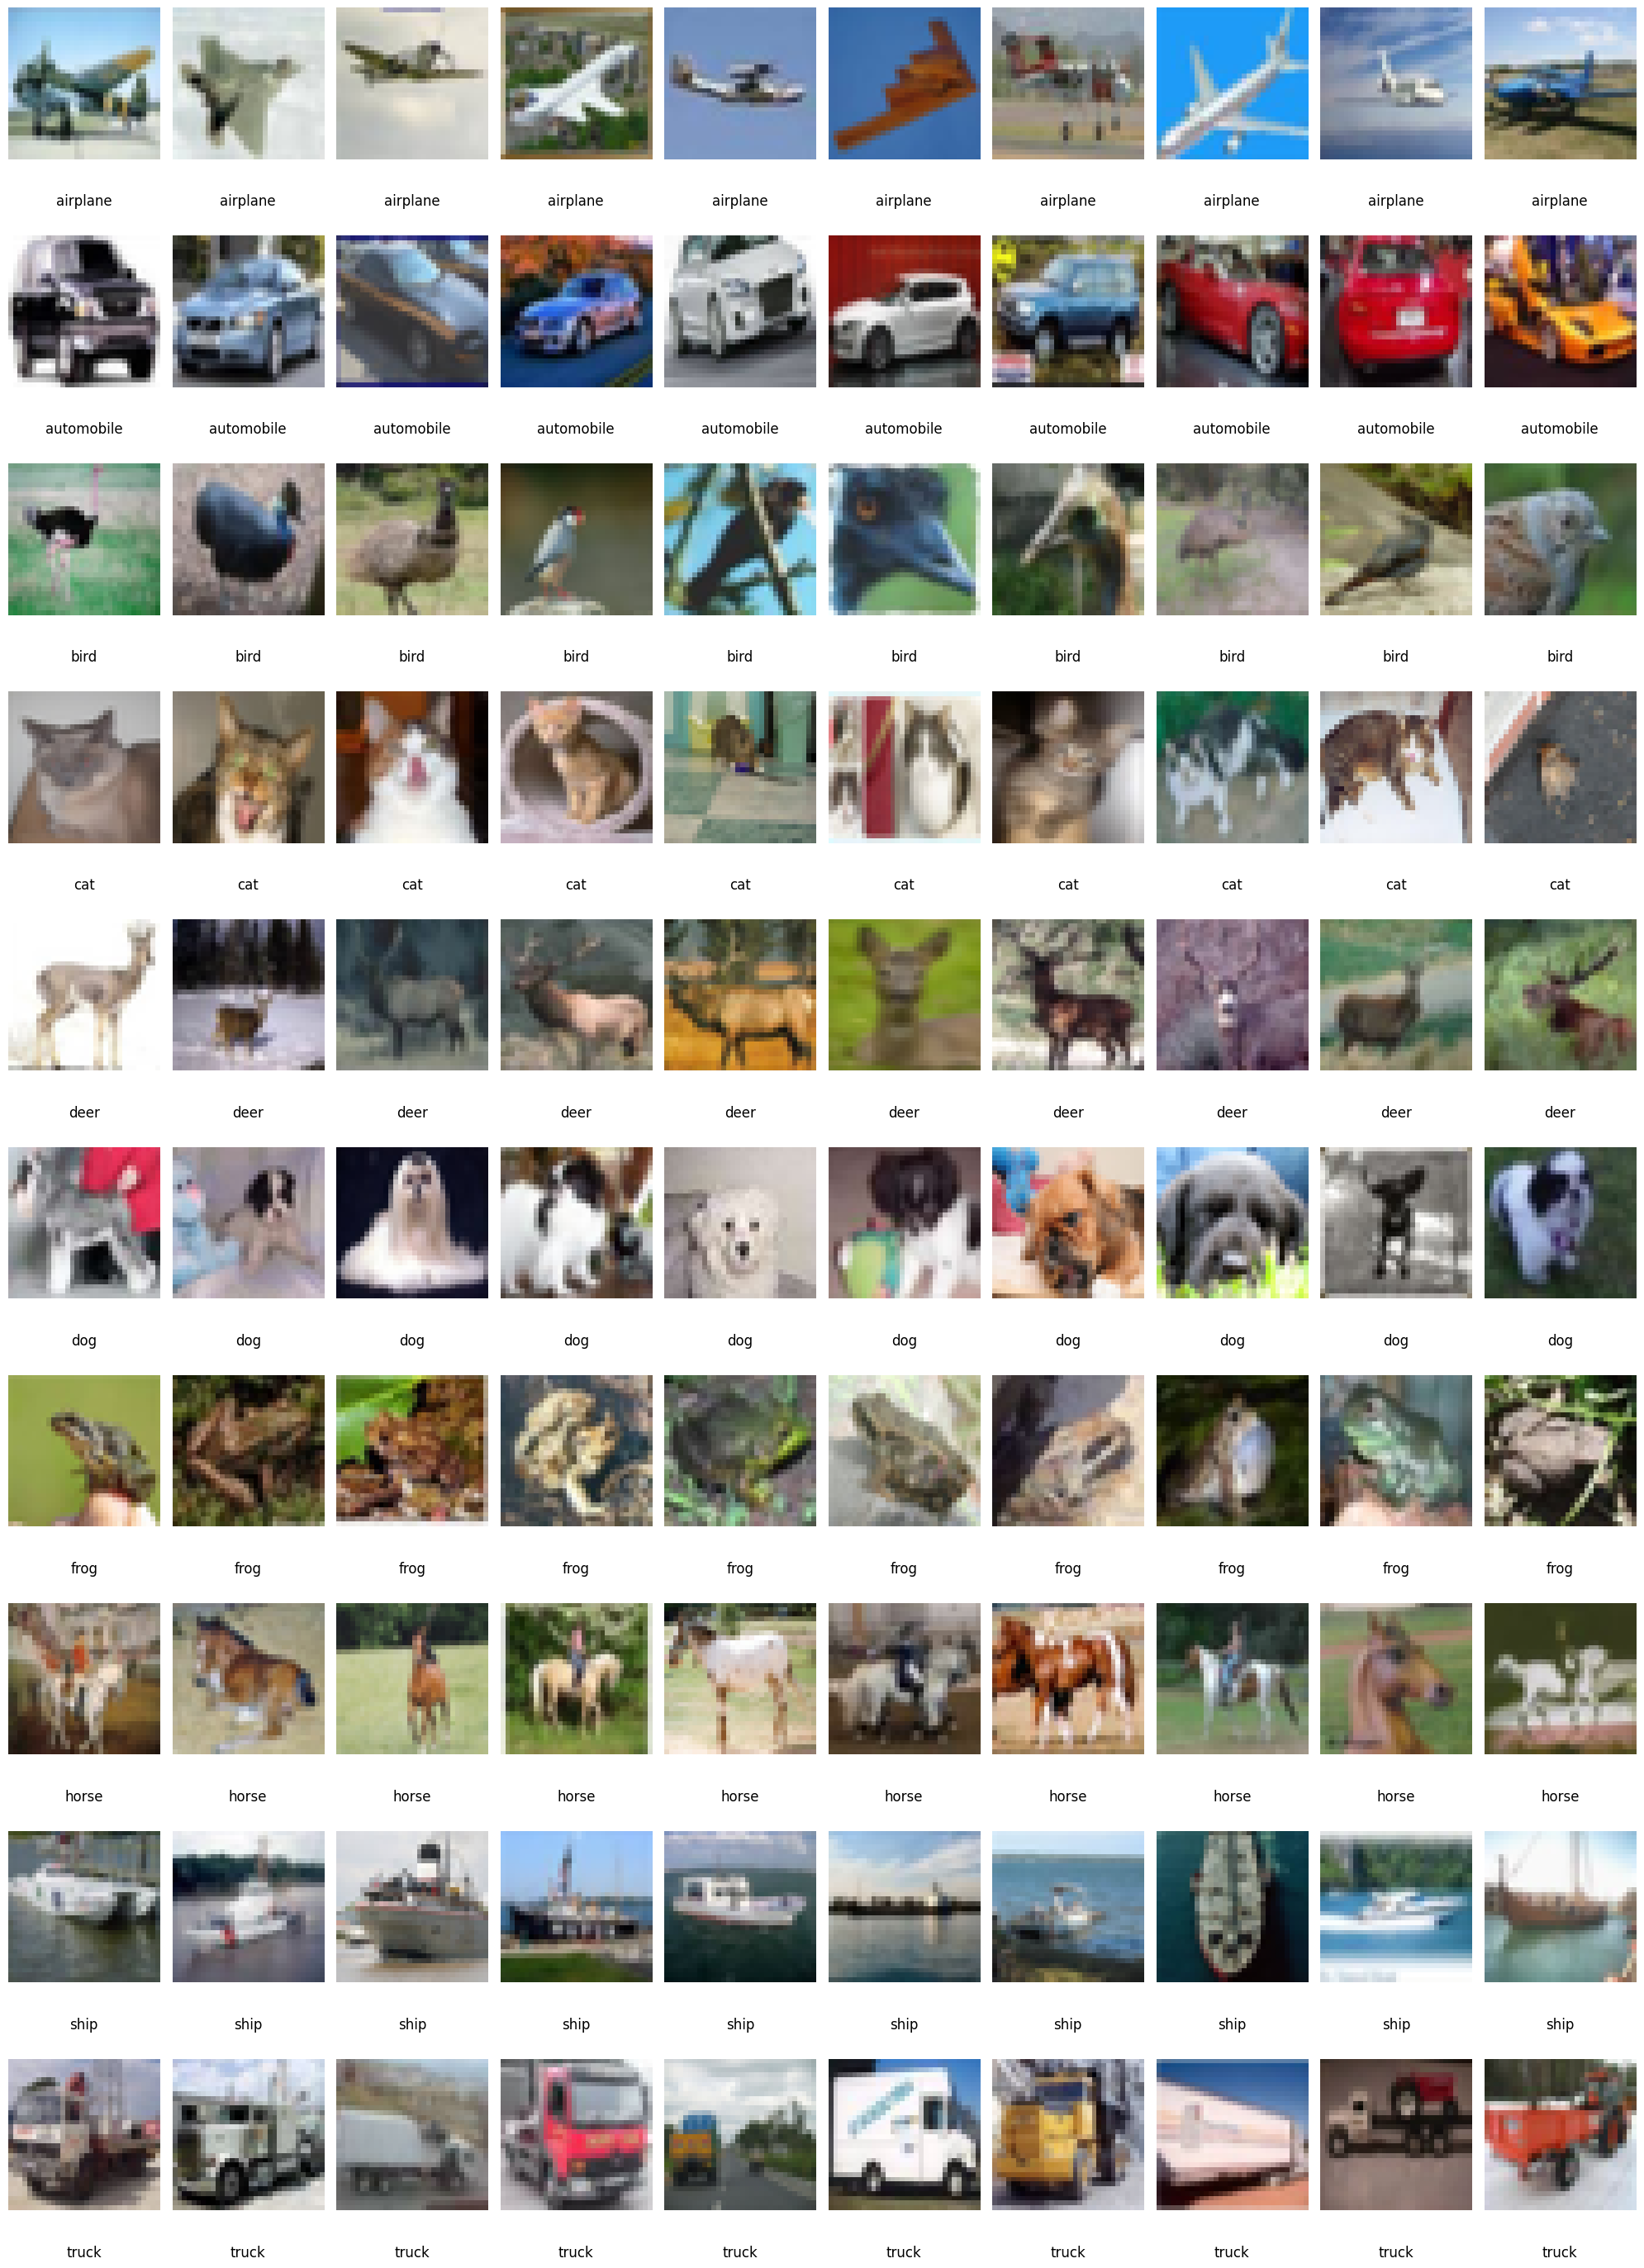

In [ ]:
plot_samples_per_class(full_train_dataset, samples_per_class=10)

## **Part II. Preprocessing**


### **Calculate mean + std of train for normalization**

In [ ]:
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

# Convert each PIL image to a PyTorch Tensor on the fly using ToTensor()
imgs = torch.stack([transforms.ToTensor()(img) for img, _ in train_dataset], dim=0)

mean = imgs.mean(dim=[0, 2, 3])
std = imgs.std(dim=[0, 2, 3])

print("Train Set Mean:", mean)
print("Train Set Std :", std)

Train Set Mean: tensor([0.4917, 0.4823, 0.4467])
Train Set Std : tensor([0.2471, 0.2435, 0.2616])


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean.tolist(), std=std.tolist())
])

In [ ]:
full_train_dataset.transform = transform

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    download=True,
    train=False,
    transform=transform
)

### **Create Data Loaders**
*Load the training and test datasets in mini-batches for model training and evaluation.*

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

## **Part III. Define architecture**

### **1— Softmax classifier**



In [ ]:
class SoftmaxClassifier(nn.Module):
  def __init__(self, input_dim , num_labels):
    super().__init__()

    # 3 channels x 32 x 32 = 3072 features
    self.model=nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_dim,
                  out_features=num_labels,
                  device=device)
    )

  def forward(self, x):
    return self.model(x)

### **2 — MLP**
3072 → 64 → 32 → 10

In [ ]:
class MLP(nn.Module):
  def __init__(self, input_dim, hidden_size=128, num_labels=10):
    super().__init__()

    # CIFAR-10 input: 3 * 32 * 32 = 3072
    self.model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_dim,
                  out_features=hidden_size,
                  device=device),
        nn.ReLU(),
        nn.Linear(in_features=hidden_size,
                  out_features=hidden_size//2,
                  device=device),
        nn.ReLU(),
        nn.Linear(in_features=hidden_size//2,
                  out_features=num_labels,
                  device=device)

    )

  def forward(self, x):
    return self.model(x)

### **3 — CNN**

In [ ]:
class ConvBlock(nn.Module):
  def __init__(self, in_channels, out_channels, kernel_size=3):
    super().__init__()

    self.conv = nn.Sequential(
        nn.Conv2d(in_channels=in_channels,
                  out_channels=out_channels,
                  kernel_size=kernel_size,
                  stride=1,
                  padding=1,
                  device=device),
        nn.ReLU(),
        nn.BatchNorm2d(out_channels, device=device),
        nn.Conv2d(in_channels=out_channels,
                  out_channels=out_channels,
                  kernel_size=kernel_size,
                  stride=1,
                  padding=1,
                  device=device),
        nn.ReLU(),
        nn.BatchNorm2d(out_channels, device=device),
        nn.MaxPool2d(kernel_size=2,
                     stride=2)
    )

  def forward(self, x):
    return self.conv(x)

class MiniVGG(nn.Module):
  def __init__(self, input_dim, hidden_units=32, num_classes=10, kernel_size=3):
    super().__init__()

    self.features=nn.Sequential(
        ConvBlock(in_channels=input_dim,
                  out_channels=hidden_units,
                  kernel_size=kernel_size),
        ConvBlock(in_channels=hidden_units,
                  out_channels=hidden_units*2))
    self.classifier=nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*2*8*8,
                  out_features=num_classes,
                  device=device)
    )

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

##**IV. Setup training environment**

###**Define evaluate function**

In [ ]:
def evaluate_one_epoch(model, dataloader, criterion, device):
  model.eval()

  total_correct = 0
  total_samples = 0
  total_loss = 0

  with torch.no_grad():
    for images, labels in dataloader:
      images, labels = images.to(device), labels.to(device)

      logits = model(images)
      loss = criterion(logits, labels)

      predictions = logits.argmax(dim=1)

      total_correct += (predictions == labels).sum().item()
      total_samples += labels.size(0)
      total_loss += loss.item() * images.size(0)

  average_loss = total_loss / total_samples
  accuracy = total_correct / total_samples

  return {
      "loss": average_loss,
      "accuracy": accuracy
  }

In [ ]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
  model.train()
  total_correct = 0
  total_samples = 0
  total_loss = 0

  for images, labels in dataloader:
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()

    logits = model(images)
    loss = criterion(logits, labels)
    loss.backward()
    optimizer.step()

    total_loss += loss.item() * images.size(0)
    predictions = logits.argmax(dim=1)
    total_correct += (predictions == labels).sum().item()
    total_samples += labels.size(0)

  return {
      "loss": total_loss / total_samples,
      "accuracy": total_correct / total_samples
  }

###**Define training function**

In [ ]:
def train_model(
    model,
    train_loader,
    val_loader,
    device,
    epochs=3,
    lr=0.001
):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = {
        "train_losses": [],
        "train_accuracies": [],
        "val_losses": [],
        "val_accuracies": [],
        "epoch_times": []
    }

    best_val_loss, best_state, best_epoch = float("inf"), None, 0


    for epoch in range(epochs):
        # Training
        start_time = time.time()
        train_result=train_one_epoch(
            model=model,
            dataloader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            device=device
        )
        end_time = time.time()

        val_result = evaluate_one_epoch(
            model=model,
            dataloader=val_loader,
            criterion=criterion,
            device=device
        )


        # Append metrics to history
        history["train_losses"].append(train_result["loss"])
        history["train_accuracies"].append(train_result["accuracy"])
        history["val_losses"].append(val_result["loss"])
        history["val_accuracies"].append(val_result["accuracy"])
        history["epoch_times"].append(end_time - start_time)

        if val_result["loss"] < best_val_loss:
            best_val_loss = val_result["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1

        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_result['loss']:.4f} | Train Acc: {train_result['accuracy']:.4f} | "
              f"Val Loss: {val_result['loss']:.4f} | Val Acc: {val_result['accuracy']:.4f}")

    torch.save(best_state, f"{model.__class__.__name__}_best.pt")
    model.load_state_dict(best_state)
    total, trainable = count_parameters(model)
    history.update(best_epoch=best_epoch, params_total=total, params_trainable=trainable)
    return model, history


### **Define count parameter function**

In [ ]:
def count_parameters(model):
  total = sum(p.numel() for p in model.parameters())
  trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
  return total, trainable

### **Plotting loss -  accuaracy curve**

In [ ]:
def plot_loss_accuracy_curves(train_losses, train_accuracies,
                              val_losses, val_accuracies,
                              title="Loss and Accuracy Curves",
                              axes=None,
):
    """
    Plot the training and validation loss and accuracy curves.
    """
    sns.set_theme(style="whitegrid")
    colors = sns.color_palette("rocket", n_colors=4)

    standalone = axes is None
    if standalone:
        _, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot Loss Curves
    epochs = range(1, len(train_losses) + 1)
    axes[0].plot(epochs, train_losses, label="Training Loss", color=colors[1], linewidth=2)
    axes[0].plot(epochs, val_losses, label="Validation Loss", color=colors[3], linewidth=2, linestyle="--")
    axes[0].set(xlabel="Epoch", ylabel="Loss", title=f"{title} Loss".strip())
    axes[0].legend()

    # Plot Accuracy Curves
    axes[1].plot(epochs, train_accuracies, label="Training Accuracy", color=colors[1], linewidth=2)
    axes[1].plot(epochs, val_accuracies, label="Validation Accuracy", color=colors[3], linewidth=2, linestyle="--")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title=f"{title} Accuracy".strip())
    axes[1].legend()

    if standalone:
        plt.tight_layout()
        plt.show()

### **Predict function for final report**

In [ ]:
def predict(model, dataloader, device):
  model.eval()

  y_true = []
  y_pred = []
  y_prob = []

  start_time = time.time()
  with torch.no_grad():
    for images, labels in dataloader:
      images, labels = images.to(device), labels.to(device)
      logits = model(images)
      predictions = logits.argmax(dim=1)
      probabilities = torch.softmax(logits, dim=1)

      # Store batch tensors directly
      y_true.append(labels.cpu())
      y_pred.append(predictions.cpu())
      y_prob.append(probabilities.cpu())
  end_time = time.time()


  # Concatenate along the first dimension (batch dimension)
  y_true = torch.cat(y_true, dim=0).numpy()
  y_pred = torch.cat(y_pred, dim=0).numpy()
  y_prob = torch.cat(y_prob, dim=0).numpy()

  return y_true, y_pred, y_prob, end_time - start_time

### **Plot confusion matrix**

In [ ]:
def plot_confusion_matrix(y_true, y_pred, classes, normalize=False,
                          title="Confusion matrix", cmap="rocket", ax=None):
  cm = metrics.confusion_matrix(y_true, y_pred,
                                labels=np.arange(len(classes)),
                                normalize="true" if normalize else None)
  standalone = ax is None
  if standalone:
    fig, ax = plt.subplots(figsize=(10, 10))
  sns.heatmap(cm,
              annot=True,
              fmt=".2f" if normalize else "d",
              cmap=cmap,
              cbar=False,
              xticklabels=classes,
              yticklabels=classes,
              ax=ax)
  ax.set_title(title)
  ax.set_xlabel("Predicted label")
  ax.set_ylabel("True label")
  ax.tick_params(axis="x", rotation=45)
  if standalone:
    plt.tight_layout()
    plt.show()

  return cm

### **Show some errors for analyzing**

In [ ]:
def show_errors(dataset, y_true, y_pred, y_prob, classes,
                n=12, num_cols=4, title="", mean=None, std=None):
  wrong_idx = np.where(y_pred != y_true)[0]
  if len(wrong_idx) == 0:
    print("No wrong predictions")
    return

  # Get top n wrong predictions with highest confidence
  conf = y_prob[wrong_idx, y_pred[wrong_idx]]
  display_n = min(n, len(wrong_idx))
  desending_conf_idx = wrong_idx[np.argsort(-conf)][:display_n]

  num_rows = int(np.ceil(display_n / num_cols))
  fig, axes = plt.subplots(num_rows, num_cols,
                           figsize=(num_cols * 3, num_rows * 3))
  axes = np.array(axes).reshape(-1)

  for i, (ax, idx) in enumerate(zip(axes, desending_conf_idx)):
    img, label = dataset[idx]

    if mean is not None and std is not None:
      img = img.clone()
      for t, m, s in zip(img, mean, std):
        t.mul_(s).add_(m)

    img = img.squeeze().cpu().numpy() \
     if img.shape[0] == 1 \
     else img.permute(1, 2, 0).cpu().numpy()

    # Clip pixel values between 0 and 1 for safe rendering
    img = np.clip(img, 0, 1)

    ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
    ax.set_title(f"True: {classes[y_true[idx]]}\n"
                 f"Pred: {classes[y_pred[idx]]} ({y_prob[idx, y_pred[idx]]:.2f})",
                 fontsize=9, color="crimson")
    ax.axis("off")

  for ax in axes[display_n:]:
    ax.axis("off")

  fig.suptitle(f"{title} - {len(wrong_idx)} errors / {len(y_true)}", fontsize=12)
  plt.tight_layout()
  plt.show()

## **Part V. Experimenting**

In [ ]:
def run_experiment(models_dict, train_loader, val_loader, test_loader, device, epochs=3, seed=42, lr=0.001):
    """
    Runs training and evaluation experiments on multiple models.
    """
    # 1. Enforce strict seed consistency at the beginning of the experiment
    set_seed(seed)

    experiment_results = {}

    for model_name, model_class_or_instance in models_dict.items():
        print(f"\n=== Running Experiment: {model_name} ===")

        # If a class or lambda is passed, instantiate it here; otherwise use deepcopy
        if isinstance(model_class_or_instance, type) or callable(model_class_or_instance):
            model = model_class_or_instance()
        else:
            model = copy.deepcopy(model_class_or_instance)

        # Train model
        model, history = train_model(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            device=device,
            epochs=epochs,
            lr=lr
        )

        # Predict and measure inference time
        y_true, y_pred, y_prob, inference_time = predict(
            model=model,
            dataloader=test_loader,
            device=device
        )

        experiment_results[model_name] = {
            "model": model,
            "history": history,
            "y_true": y_true,
            "y_pred": y_pred,
            "y_prob": y_prob,
            "inference_time": inference_time
        }

    return experiment_results

### **Start experimenting**

In [ ]:

models = {
    "SoftmaxClassifier": lambda: SoftmaxClassifier(input_dim=32*32*3, num_labels=10),
    "MLP": lambda: MLP(input_dim=32*32*3, hidden_size=64, num_labels=10),
    "MiniVGG": lambda: MiniVGG(input_dim=3, hidden_units=16, num_classes=10, kernel_size=3)
}

results = run_experiment(
    models_dict=models,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    device=device,
    epochs=10,
    seed=42,
    lr=0.001
)


=== Running Experiment: SoftmaxClassifier ===
Epoch 1/10 | Train Loss: 1.9901 | Train Acc: 0.3421 | Val Loss: 2.0423 | Val Acc: 0.3390
Epoch 2/10 | Train Loss: 1.9003 | Train Acc: 0.3652 | Val Loss: 1.9609 | Val Acc: 0.3468
Epoch 3/10 | Train Loss: 1.8923 | Train Acc: 0.3678 | Val Loss: 1.9813 | Val Acc: 0.3490
Epoch 4/10 | Train Loss: 1.8769 | Train Acc: 0.3770 | Val Loss: 1.9601 | Val Acc: 0.3558
Epoch 5/10 | Train Loss: 1.8584 | Train Acc: 0.3822 | Val Loss: 1.9856 | Val Acc: 0.3388
Epoch 6/10 | Train Loss: 1.8538 | Train Acc: 0.3847 | Val Loss: 1.9283 | Val Acc: 0.3548
Epoch 7/10 | Train Loss: 1.8434 | Train Acc: 0.3906 | Val Loss: 1.9674 | Val Acc: 0.3594
Epoch 8/10 | Train Loss: 1.8301 | Train Acc: 0.3910 | Val Loss: 1.9737 | Val Acc: 0.3508
Epoch 9/10 | Train Loss: 1.8317 | Train Acc: 0.3906 | Val Loss: 2.0310 | Val Acc: 0.3446
Epoch 10/10 | Train Loss: 1.8254 | Train Acc: 0.3928 | Val Loss: 1.9475 | Val Acc: 0.3648

=== Running Experiment: MLP ===
Epoch 1/10 | Train Loss: 1.70

### **Plot necessary chart**

In [ ]:
sns.set_theme(style="whitegrid")
names = list(results.keys())

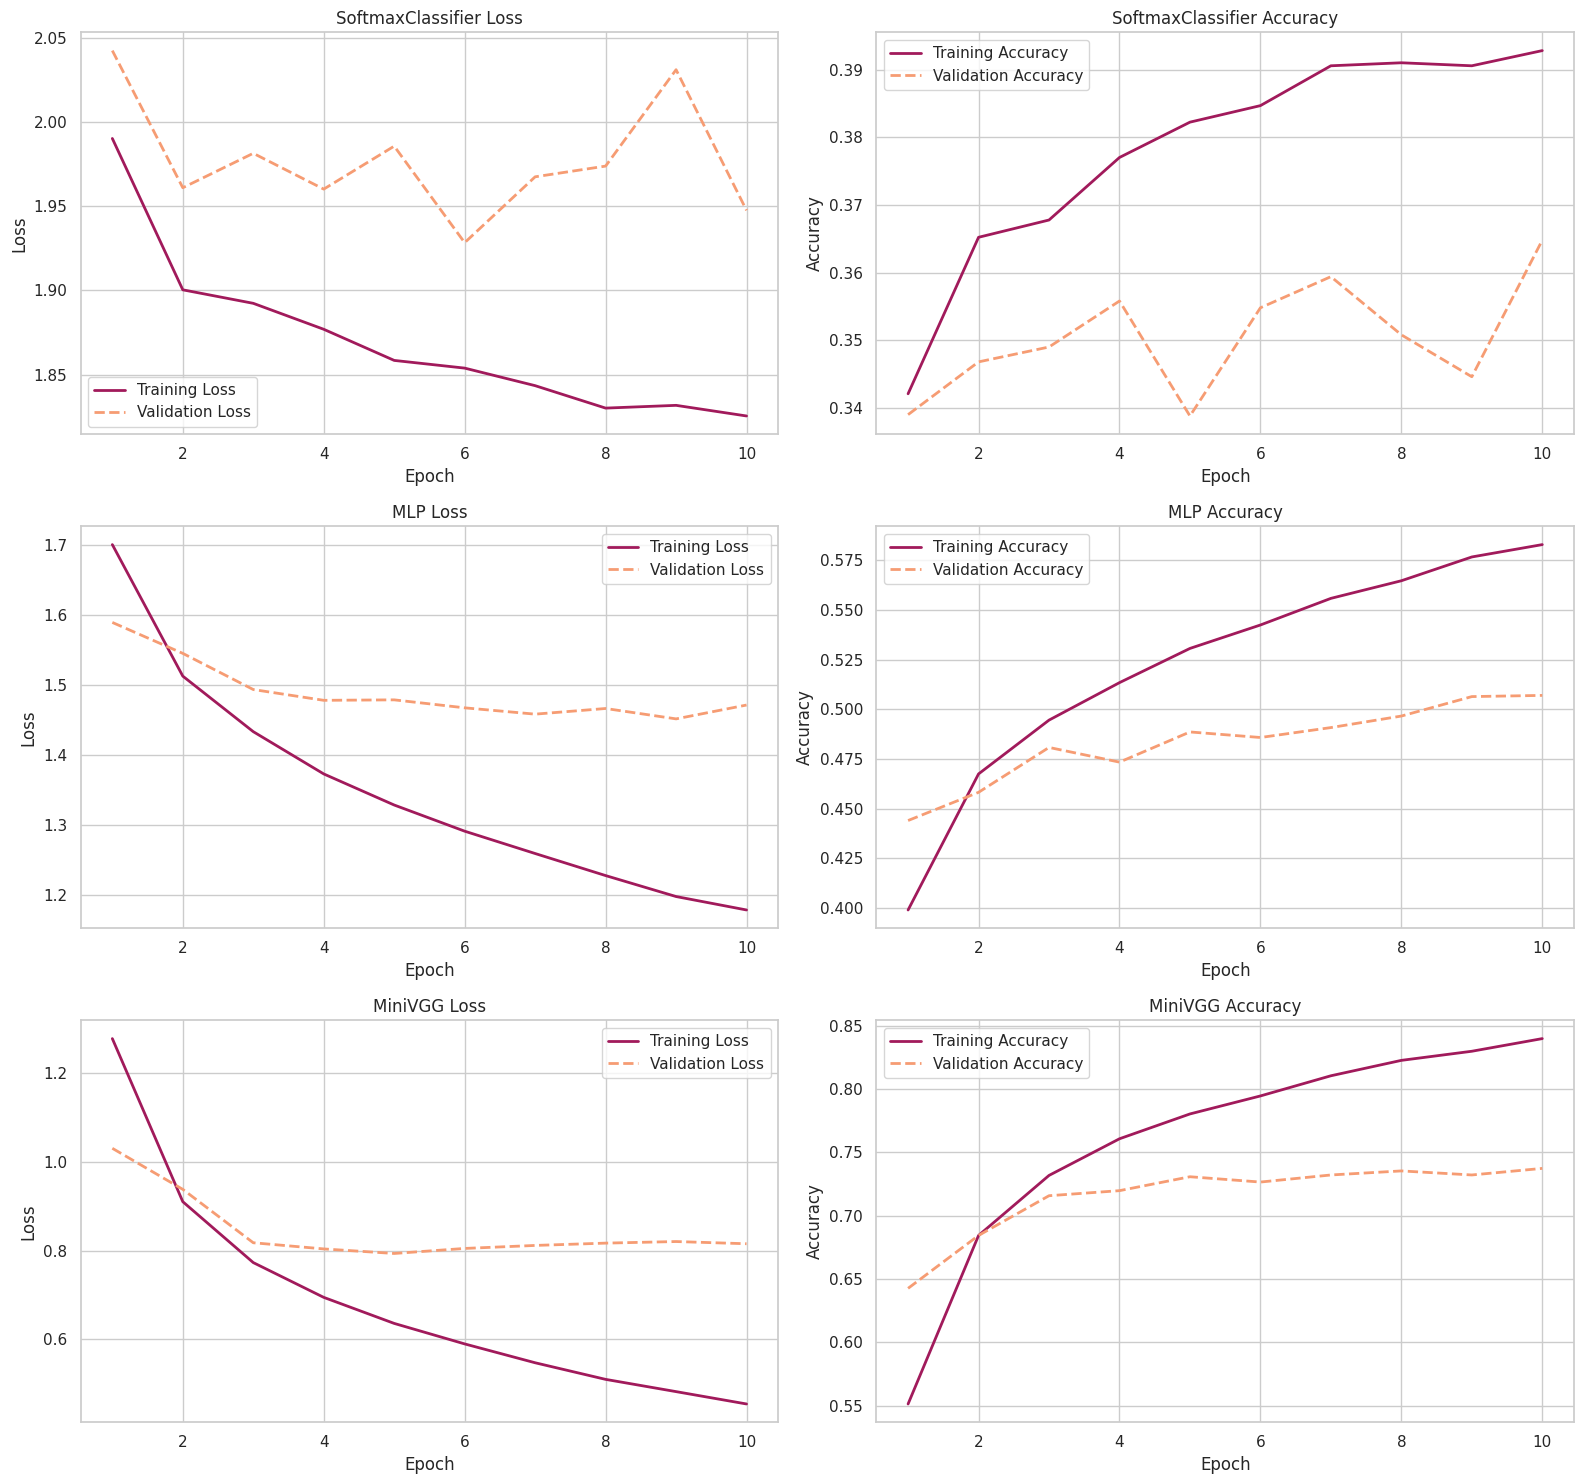

In [ ]:
# 1. Plot Loss and Accuracy Curves side-by-side for all models
fig, axes = plt.subplots(len(results), 2, figsize=(16, 5*len(results)))
if len(results) == 1:
    axes = np.expand_dims(axes, axis=0)

for idx, (model_name, res) in enumerate(results.items()):
    history = res["history"]
    plot_loss_accuracy_curves(
        train_losses=history["train_losses"],
        train_accuracies=history["train_accuracies"],
        val_losses=history["val_losses"],
        val_accuracies=history["val_accuracies"],
        title=model_name,
        axes=axes[idx]
    )
plt.tight_layout()
plt.show()


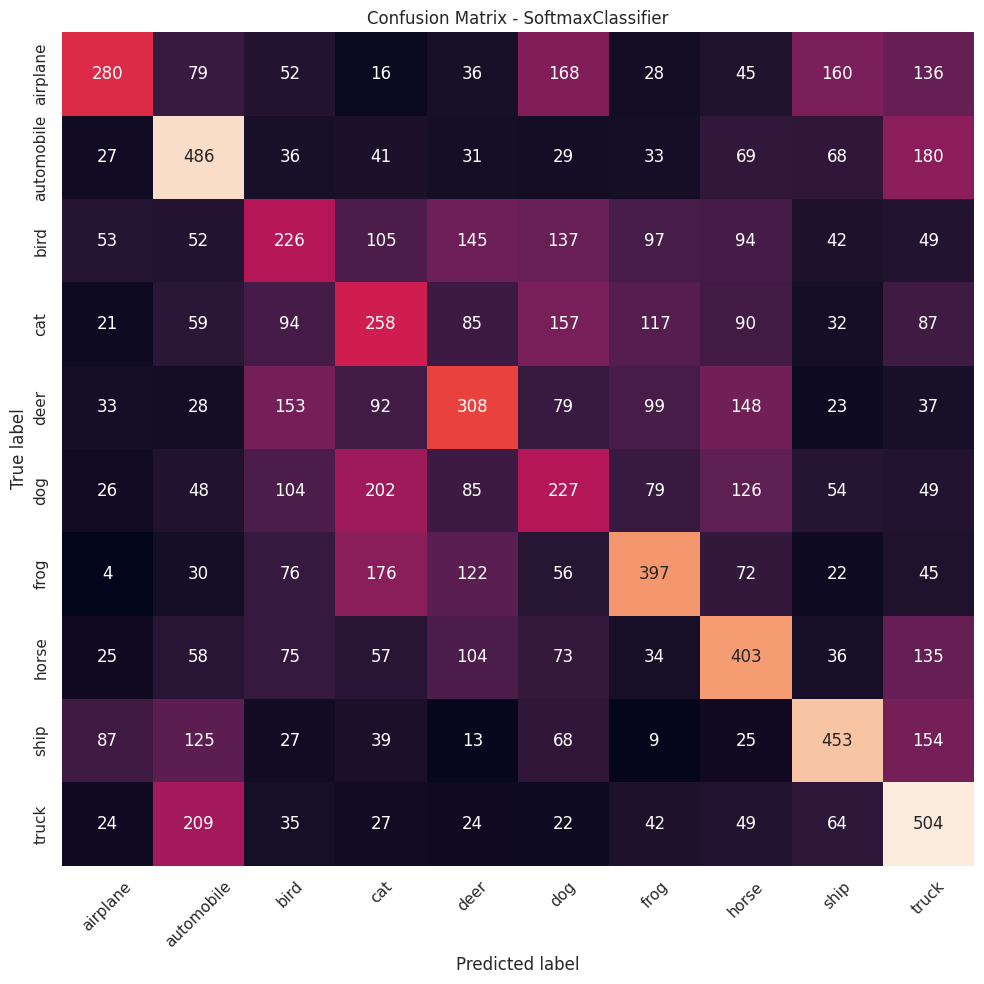

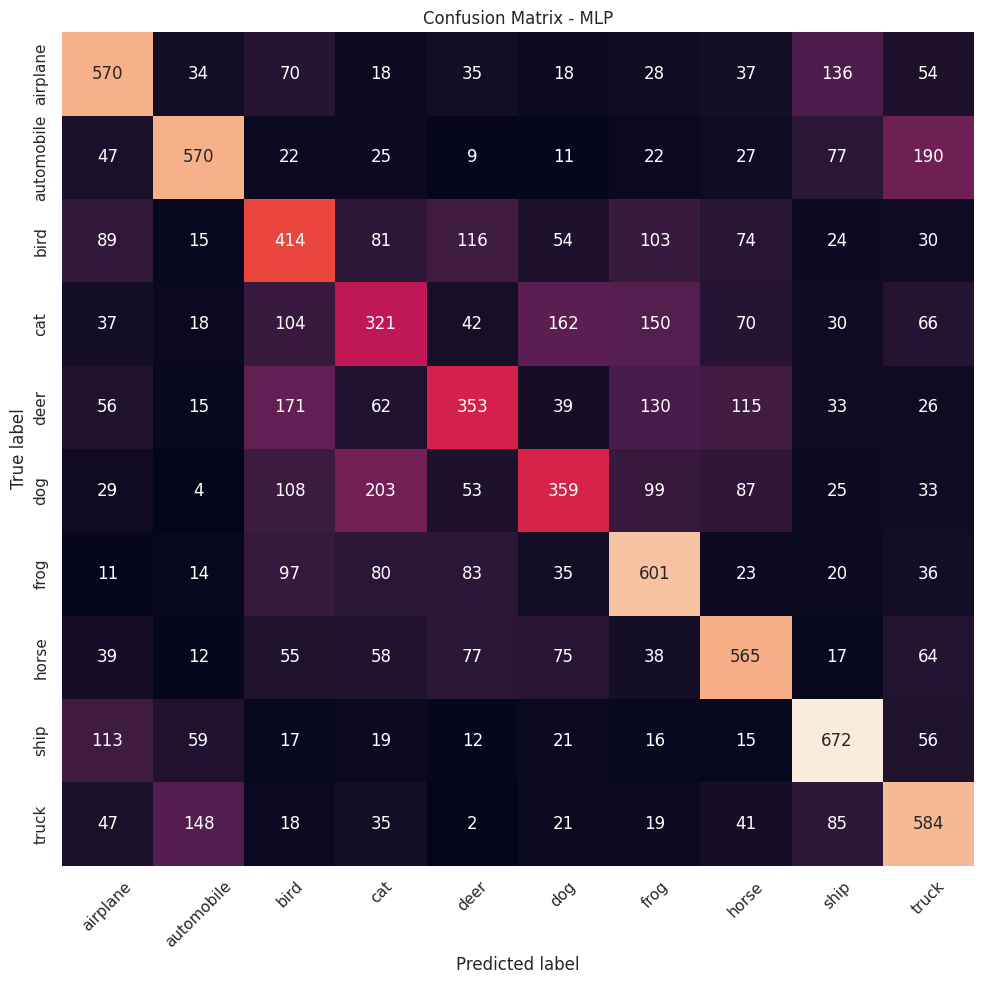

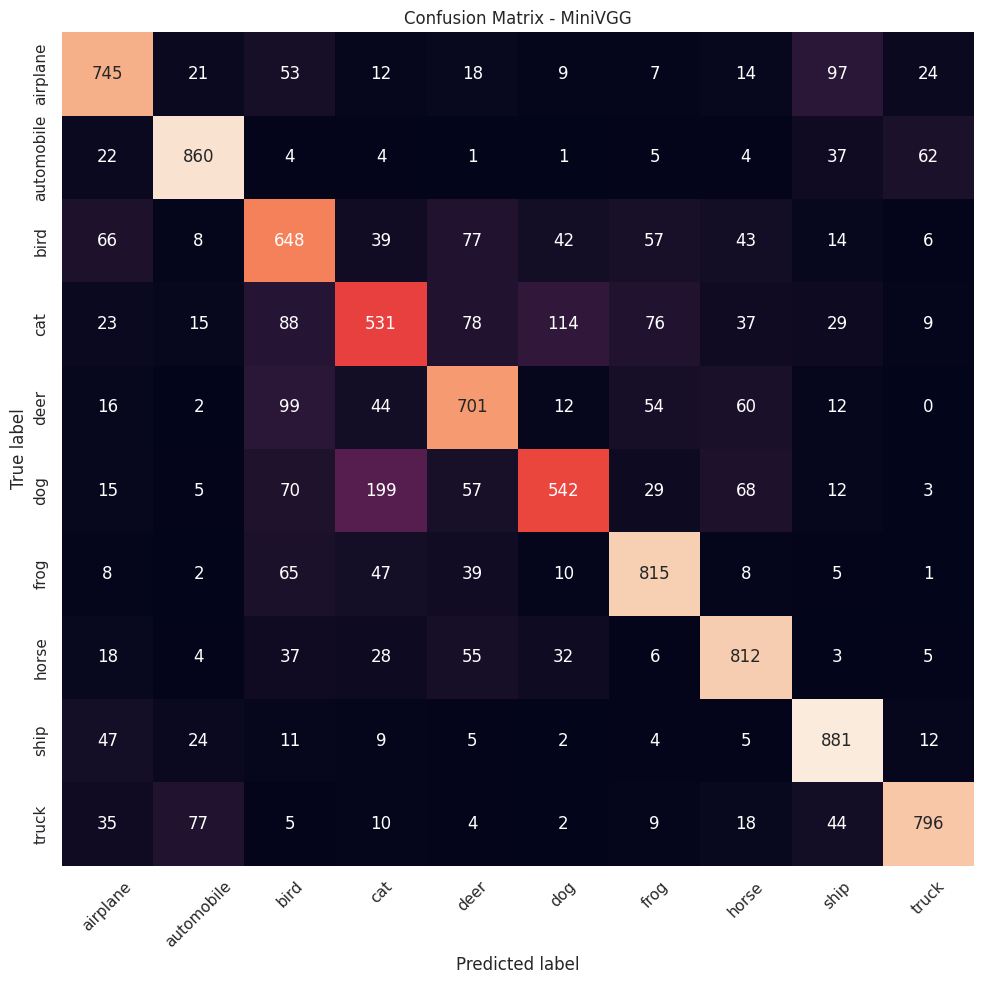

In [ ]:
# 2. Plot Confusion Matrix for each model
for model_name, res in results.items():
    plot_confusion_matrix(
        y_true=res["y_true"],
        y_pred=res["y_pred"],
        classes=full_train_dataset.classes,
        normalize=False,
        title=f"Confusion Matrix - {model_name}"
    )

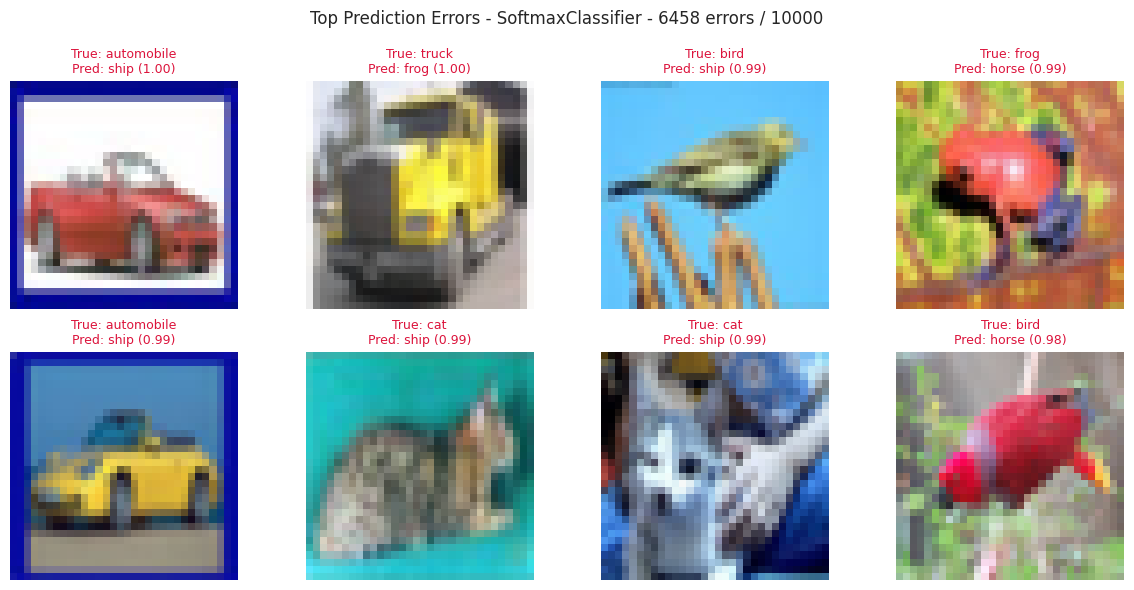

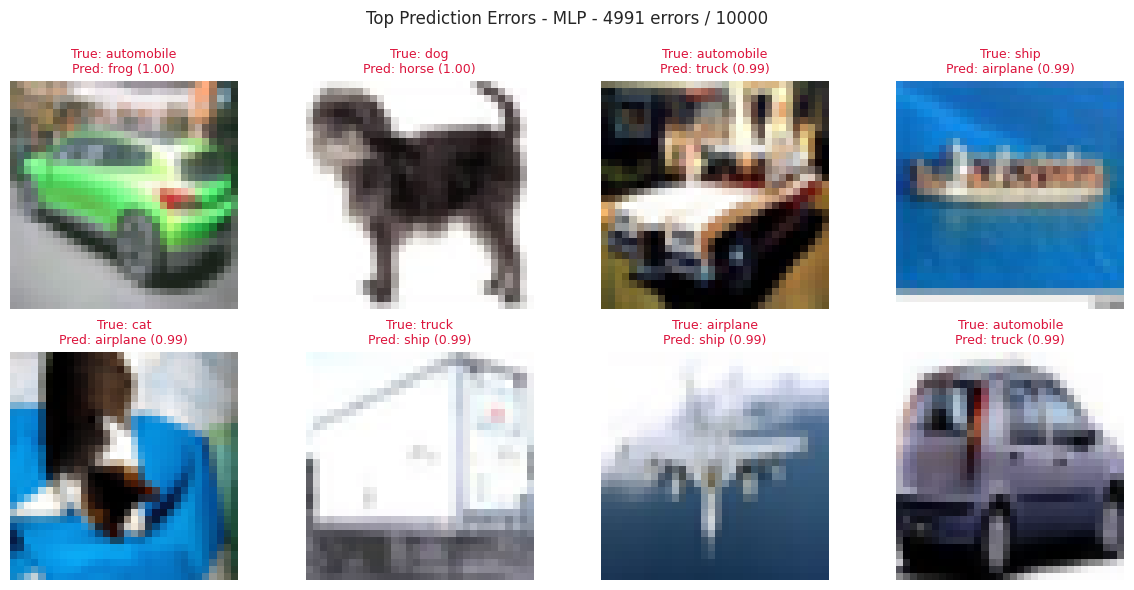

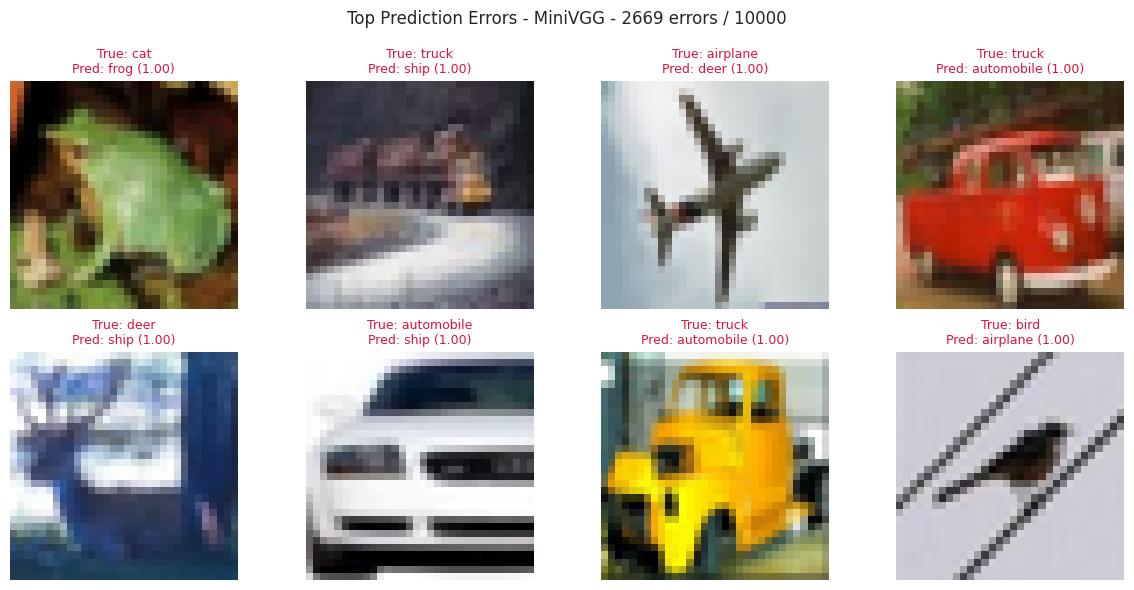

In [ ]:
# 3. Show top classification errors for each model
for model_name, res in results.items():
    show_errors(
        dataset=test_dataset,
        y_true=res["y_true"],
        y_pred=res["y_pred"],
        y_prob=res["y_prob"],
        classes=full_train_dataset.classes,
        n=8,
        num_cols=4,
        title=f"Top Prediction Errors - {model_name}",
        mean=mean.tolist(),
        std=std.tolist()
    )

In [ ]:
def plot_accuracy(results):
    model_names = list(results.keys())
    accuracies = [(results[m]["y_pred"] == results[m]["y_true"]).mean() * 100 for m in model_names]

    sns.set_theme(style="white")
    plt.figure(figsize=(6, 5))
    colors = sns.color_palette("rocket", n_colors=len(model_names))

    ax = sns.barplot(x=model_names, y=accuracies, palette=colors, hue=model_names, legend=False)
    plt.title("Test Accuracy (%)", fontsize=12, fontweight="bold")
    plt.ylabel("Accuracy (%)")
    plt.ylim(0, max(accuracies) * 1.15)

    for idx, val in enumerate(accuracies):
        ax.text(idx, val + (max(accuracies) * 0.02), f"{val:.2f}%", ha="center", va="bottom", fontweight="bold")

    plt.tight_layout()
    plt.show()

def plot_training_time(results):
    model_names = list(results.keys())
    training_times = [sum(results[m]["history"]["epoch_times"]) for m in model_names]

    sns.set_theme(style="white")
    plt.figure(figsize=(6, 5))
    colors = sns.color_palette("rocket", n_colors=len(model_names))

    ax = sns.barplot(x=model_names, y=training_times, palette=colors, hue=model_names, legend=False)
    plt.title("Training Time (seconds)", fontsize=12, fontweight="bold")
    plt.ylabel("Time (s)")
    plt.ylim(0, max(training_times) * 1.15)

    for idx, val in enumerate(training_times):
        ax.text(idx, val + (max(training_times) * 0.02), f"{val:.2f}s", ha="center", va="bottom", fontweight="bold")

    plt.tight_layout()
    plt.show()

def plot_inference_time(results, test_dataset):
    model_names = list(results.keys())
    # Calculate inference time per sample (in milliseconds for better readability)
    inf_times_per_sample = [(results[m]["inference_time"] / len(test_dataset)) * 1000 for m in model_names]

    sns.set_theme(style="white")
    plt.figure(figsize=(6, 5))
    colors = sns.color_palette("rocket", n_colors=len(model_names))

    ax = sns.barplot(x=model_names, y=inf_times_per_sample, palette=colors, hue=model_names, legend=False)
    plt.title("Inference Time per Sample (ms)", fontsize=12, fontweight="bold")
    plt.ylabel("Time (ms)")
    plt.ylim(0, max(inf_times_per_sample) * 1.15)

    for idx, val in enumerate(inf_times_per_sample):
        ax.text(idx, val + (max(inf_times_per_sample) * 0.02), f"{val:.4f} ms", ha="center", va="bottom", fontweight="bold")

    plt.tight_layout()
    plt.show()

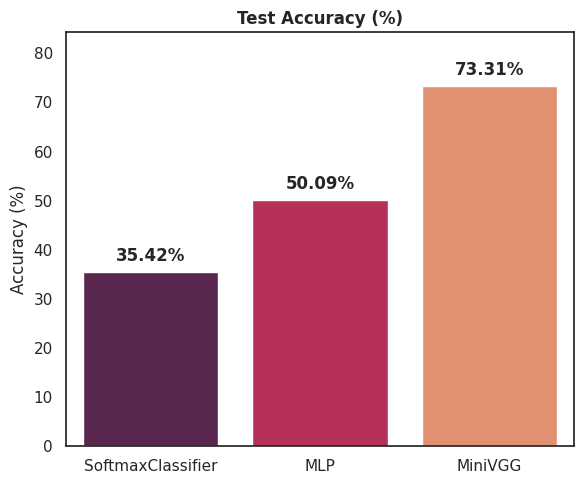

In [ ]:
plot_accuracy(results)

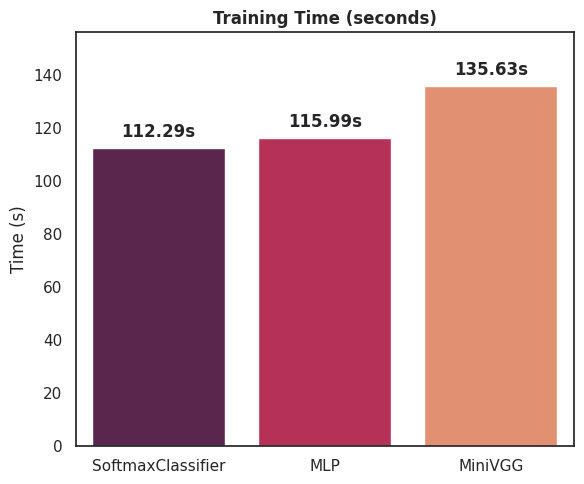

In [ ]:
plot_training_time(results)

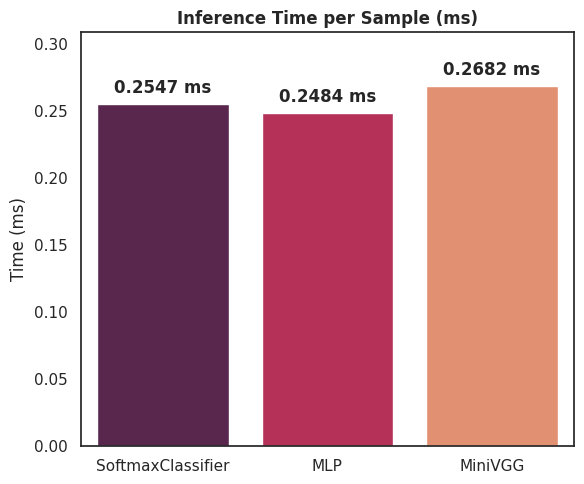

In [ ]:
plot_inference_time(results, test_dataset)

In [ ]:
def plot_number_of_parameters(results):
    import pandas as pd
    model_names = list(results.keys())
    trainable_params = [results[m]["history"]["params_trainable"] for m in model_names]

    # Create a DataFrame for easy plotting with seaborn
    data = []
    for name, trainable in zip(model_names, trainable_params):
        data.append({"Model": name, "Parameters": trainable, "Type": "Trainable"})
    df_plot = pd.DataFrame(data)

    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(10, 6))

    # Plot grouped bar chart with a 3-color palette matching each model
    colors = sns.color_palette("rocket", n_colors=len(model_names))
    ax = sns.barplot(x="Model", y="Parameters", hue="Model", data=df_plot, palette=colors, legend=False)

    plt.title("Number of Parameters per Model", fontsize=14, fontweight="bold")
    plt.xlabel("Model", fontsize=12)
    plt.ylabel("Count", fontsize=12)

    # Add values on top of the bars
    for p in ax.patches:
        val = int(p.get_height())
        if val > 0:
            ax.annotate(f"{val:,}",
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center',
                        xytext=(0, 9),
                        textcoords='offset points',
                        fontweight='bold', fontsize=9)

    plt.tight_layout()
    plt.show()

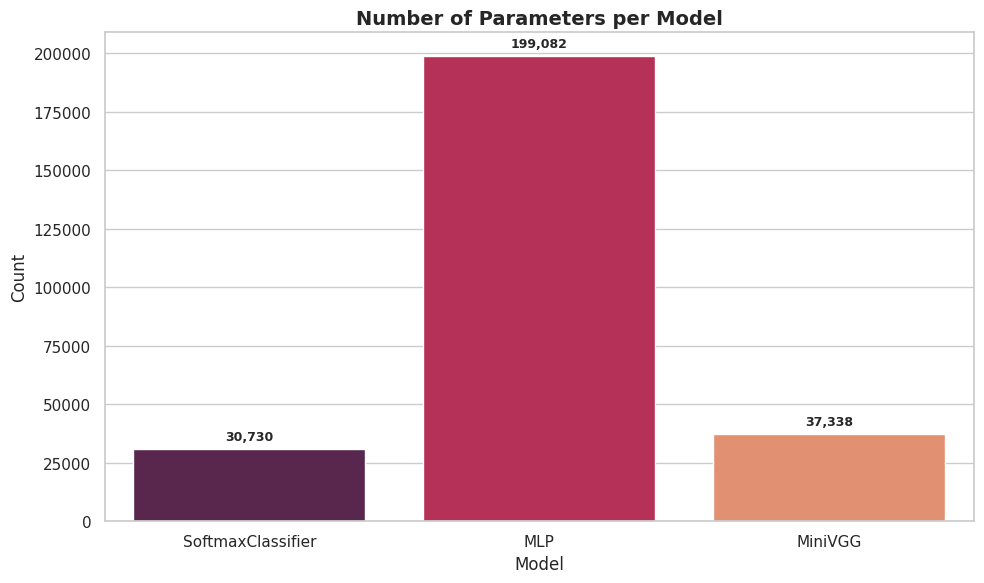

In [ ]:
plot_number_of_parameters(results)